<a href="https://colab.research.google.com/github/muriloferreira26032007-png/intro-data-science/blob/main/projeto_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predição da Doença de Alzheimer a partir de Características Clínicas e Demográficas

**Disciplina:** SME0828 – Introdução à Ciência de Dados (ICMC – USP)  
**Professor:** Francisco Rodrigues  
**Aluno:** Murilo Mendonça Ferreira *(Projeto Individual)*  
**Base de dados:** `alzheimers_disease_data.csv` (2.149 pacientes e 32 atributos preditores)  
**Tipo de problema:** Aprendizado Supervisionado — Classificação Binária (`Diagnosis`: 0 = Sem Alzheimer, 1 = Com Alzheimer)

## Questão Fundamental
**É possível prever o diagnóstico da Doença de Alzheimer dadas algumas características clínicas, cognitivas, funcionais e demográficas de um paciente?**

## Hipóteses (Método Científico)
* **Hipótese Principal ($H_1$):** Indicadores cognitivos, funcionais e sintomas comportamentais (como `MMSE`, `FunctionalAssessment`, `ADL`, `MemoryComplaints` e `BehavioralProblems`) possuem forte associação com o diagnóstico e permitem que modelos de classificação  prevejam a doença com um bom desempenho.
* **Hipótese Secundária ($H_2$):** Variáveis demográficas, histórico familiar e hábitos de vida (como idade, IMC, histórico familiar e qualidade do sono) também contribuem de forma relevante para a predição — hipótese que será testada empiricamente para ser confirmada ou refutada na análise.

## Objetivo
Percorrer o ciclo completo de Ciência de Dados — preparação dos dados, análise exploratória, modelagem, comparação de métricas, seleção/engenharia de atributos e discussão crítica — para responder à questão fundamental e identificar quais atributos realmente sustentam o diagnóstico.

## Detalhes
Por se tratar de um problema de triagem médica, o foco da avaliação prioriza o aumento do Recall (sensibilidade), buscando reduzir Falsos Negativos mesmo que isso implique uma leve queda na Precisão.

## Problema

O problema é de **classificação supervisionada binária**: `1` indica que o paciente possui Alzheimer e `0` indica que não possui.



## 1.Preparação dos dados

* Importar as bibliotecas

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
import os
from google.colab import drive
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier



RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

* Download dos dados e a remoção de atributos irrelevantes  no caso 'DoctorInCharge' e 'PatientID' pois eles não ajudam a fazer nenhuma previsão e não há nenhum dado faltante na base de dados nem dados duplicados

In [ ]:
drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive')

df = pd.read_csv("alzheimers_disease_data.csv")



cols_to_float = ['Age', 'SystolicBP', 'DiastolicBP']
df[cols_to_float] = df[cols_to_float].astype(float)



#remover a variavel DoctorInCharge     que não nos ajudará muito
df=df.drop(columns=['DoctorInCharge','PatientID'])
cols_int = df.select_dtypes(include='int64').columns.tolist()

cols_to_float = ['Age', 'SystolicBP', 'DiastolicBP']
df[cols_to_float] = df[cols_to_float].astype(float)


for i in cols_int:
 print(df[i].value_counts())


#ver os tipos de variaveis
print(df.dtypes)
#ver se há dados faltantes
print(df.isna().sum().sum())
#ver se há dados duplicados
print(df.duplicated().sum())

Mounted at /content/drive
Gender
1    1088
0    1061
Name: count, dtype: int64
Ethnicity
0    1278
1     454
3     211
2     206
Name: count, dtype: int64
EducationLevel
1    854
2    636
0    446
3    213
Name: count, dtype: int64
Smoking
0    1529
1     620
Name: count, dtype: int64
FamilyHistoryAlzheimers
0    1607
1     542
Name: count, dtype: int64
CardiovascularDisease
0    1839
1     310
Name: count, dtype: int64
Diabetes
0    1825
1     324
Name: count, dtype: int64
Depression
0    1718
1     431
Name: count, dtype: int64
HeadInjury
0    1950
1     199
Name: count, dtype: int64
Hypertension
0    1829
1     320
Name: count, dtype: int64
MemoryComplaints
0    1702
1     447
Name: count, dtype: int64
BehavioralProblems
0    1812
1     337
Name: count, dtype: int64
Confusion
0    1708
1     441
Name: count, dtype: int64
Disorientation
0    1809
1     340
Name: count, dtype: int64
PersonalityChanges
0    1825
1     324
Name: count, dtype: int64
DifficultyCompletingTasks
0    1808
1 

## 2.Descrição estatística dos dados

* As variaveis 'FunctionalAssessment', 'ADL' e 'MMSE'  lideram a correlação númerica enquanto as outras variavies númericas a correlação é bem proxima a 0


Correlação linear (Pearson) — Variáveis numéricas:


,Age,BMI,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,MMSE,FunctionalAssessment,ADL,Diagnosis
Age,1.00,-0.02,0.01,-0.01,-0.02,0.05,-0.01,-0.00,0.00,0.00,0.01,-0.00,-0.00,0.01,-0.04,-0.01
BMI,-0.02,1.00,-0.01,0.00,0.02,-0.01,-0.02,-0.00,0.00,0.02,0.04,-0.02,-0.00,-0.03,-0.01,0.03
AlcoholConsumption,0.01,-0.01,1.00,0.02,0.02,-0.00,-0.03,-0.01,-0.03,-0.02,-0.00,0.02,-0.01,-0.02,-0.01,-0.01
PhysicalActivity,-0.01,0.00,0.02,1.00,0.01,-0.00,-0.00,-0.01,0.01,0.02,-0.00,0.03,-0.01,-0.00,-0.01,0.01
DietQuality,-0.02,0.02,0.02,0.01,1.00,0.05,0.01,0.01,-0.02,-0.02,-0.01,0.03,0.02,-0.01,-0.01,0.01
SleepQuality,0.05,-0.01,-0.00,-0.00,0.05,1.00,-0.03,0.01,0.01,0.01,0.02,0.02,0.01,0.03,0.01,-0.06
SystolicBP,-0.01,-0.02,-0.03,-0.00,0.01,-0.03,1.00,0.00,0.02,-0.01,0.00,-0.03,-0.00,0.01,0.02,-0.02
DiastolicBP,-0.00,-0.00,-0.01,-0.01,0.01,0.01,0.00,1.00,0.02,-0.02,0.01,-0.01,-0.03,0.03,-0.00,0.01
CholesterolTotal,0.00,0.00,-0.03,0.01,-0.02,0.01,0.02,0.02,1.00,0.01,0.01,-0.00,-0.01,-0.01,0.00,0.01
CholesterolLDL,0.00,0.02,-0.02,0.02,-0.02,0.01,-0.01,-0.02,0.01,1.00,-0.04,-0.01,0.03,-0.02,-0.02,-0.03


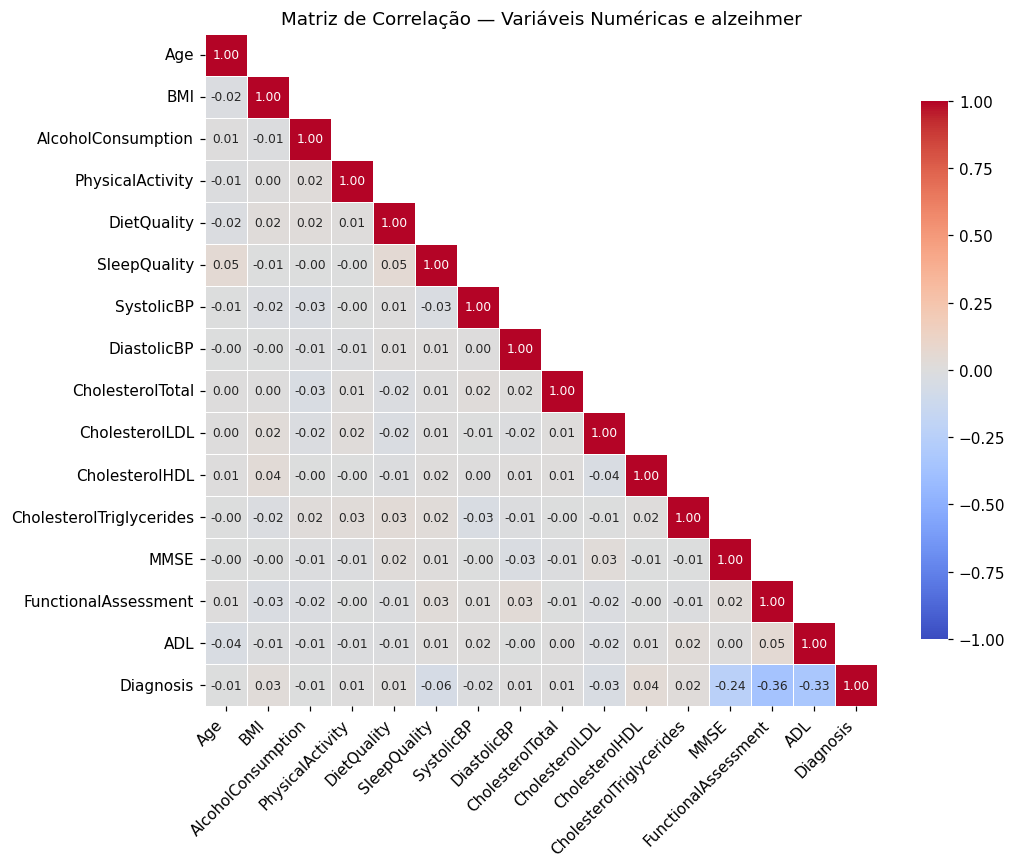

In [ ]:
# 2.4 Matriz de correlação numérica
a=df.copy()
a["Diagnosis"] = a["Diagnosis"].astype(float)
cols_corr = a.select_dtypes(include='float64').columns.tolist()
corr_mat = a[cols_corr].corr()
print("\nCorrelação linear (Pearson) — Variáveis numéricas:")
display(corr_mat.round(2))

# Triângulo superior escondido (a matriz é simétrica, então é informação repetida)
mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_mat, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
)
plt.xticks(rotation=45, ha="right")
plt.title("Matriz de Correlação — Variáveis Numéricas e Alzheimer")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import chi2_contingency

alvo = "Diagnosis"
ordinais = ["EducationLevel"]
nominais = ["Ethnicity"]
num = df.select_dtypes(include="number").drop(columns=["PatientID", "DoctorInCharge"], errors="ignore")
binarias = [c for c in num.columns if num[c].nunique() == 2 and c != alvo]
continuas = [c for c in num.columns if c not in binarias + ordinais + nominais + [alvo]]

def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    chi2 = chi2_contingency(tab)[0]
    n = tab.values.sum()
    return np.sqrt((chi2 / n) / (min(tab.shape) - 1))

res = []
for c in continuas + binarias:
    res.append((c, df[c].corr(df[alvo]), "Pearson / ponto-bisserial"))
for c in ordinais:
    res.append((c, df[c].corr(df[alvo], method="spearman"), "Spearman"))
for c in nominais:
    res.append((c, cramers_v(df[c], df[alvo]), "Cramér's V (sem sinal)"))

tabela = pd.DataFrame(res, columns=["variavel", "associacao", "medida"]).sort_values("associacao")
display(tabela.round(3))

,variavel,associacao,medida
13,FunctionalAssessment,-0.365,Pearson / ponto-bisserial
14,ADL,-0.332,Pearson / ponto-bisserial
12,MMSE,-0.237,Pearson / ponto-bisserial
5,SleepQuality,-0.057,Pearson / ponto-bisserial
30,EducationLevel,-0.043,Spearman
17,FamilyHistoryAlzheimers,-0.033,Pearson / ponto-bisserial
9,CholesterolLDL,-0.032,Pearson / ponto-bisserial
19,Diabetes,-0.032,Pearson / ponto-bisserial
26,Disorientation,-0.025,Pearson / ponto-bisserial
21,HeadInjury,-0.021,Pearson / ponto-bisserial


Taxa global de Diagnosis: 35.37%  (n = 2149)
Resumo de Diagnosis (%) e tamanho amostral por categoria:

--- Gender ---


,n,diagnosticos,pct_base,taxa_diag_pct
Gender,,,,
0,1061,386,49.37,36.38
1,1088,374,50.63,34.38



--- Ethnicity ---


,n,diagnosticos,pct_base,taxa_diag_pct
Ethnicity,,,,
2,206,84,9.59,40.78
0,1278,463,59.47,36.23
1,454,146,21.13,32.16
3,211,67,9.82,31.75



--- EducationLevel ---


,n,diagnosticos,pct_base,taxa_diag_pct
EducationLevel,,,,
0,446,174,20.75,39.01
1,854,302,39.74,35.36
2,636,217,29.60,34.12
3,213,67,9.91,31.46


... (26 outputs left out)


--- Forgetfulness ---


,n,diagnosticos,pct_base,taxa_diag_pct
Forgetfulness,,,,
0,1501,531,69.85,35.38
1,648,229,30.15,35.34



Ranking das categóricas (amplitude em pontos percentuais):


,variavel,amplitude_pp,p_valor
0,MemoryComplaints,36.13,0.0000
1,BehavioralProblems,29.50,0.0000
2,Ethnicity,9.03,0.0978
3,EducationLevel,7.55,0.2165
4,Hypertension,4.72,0.1181
5,CardiovascularDisease,4.28,0.1628
6,Diabetes,4.21,0.1622
7,FamilyHistoryAlzheimers,3.62,0.1407
8,HeadInjury,3.53,0.3603
9,Disorientation,3.23,0.2798


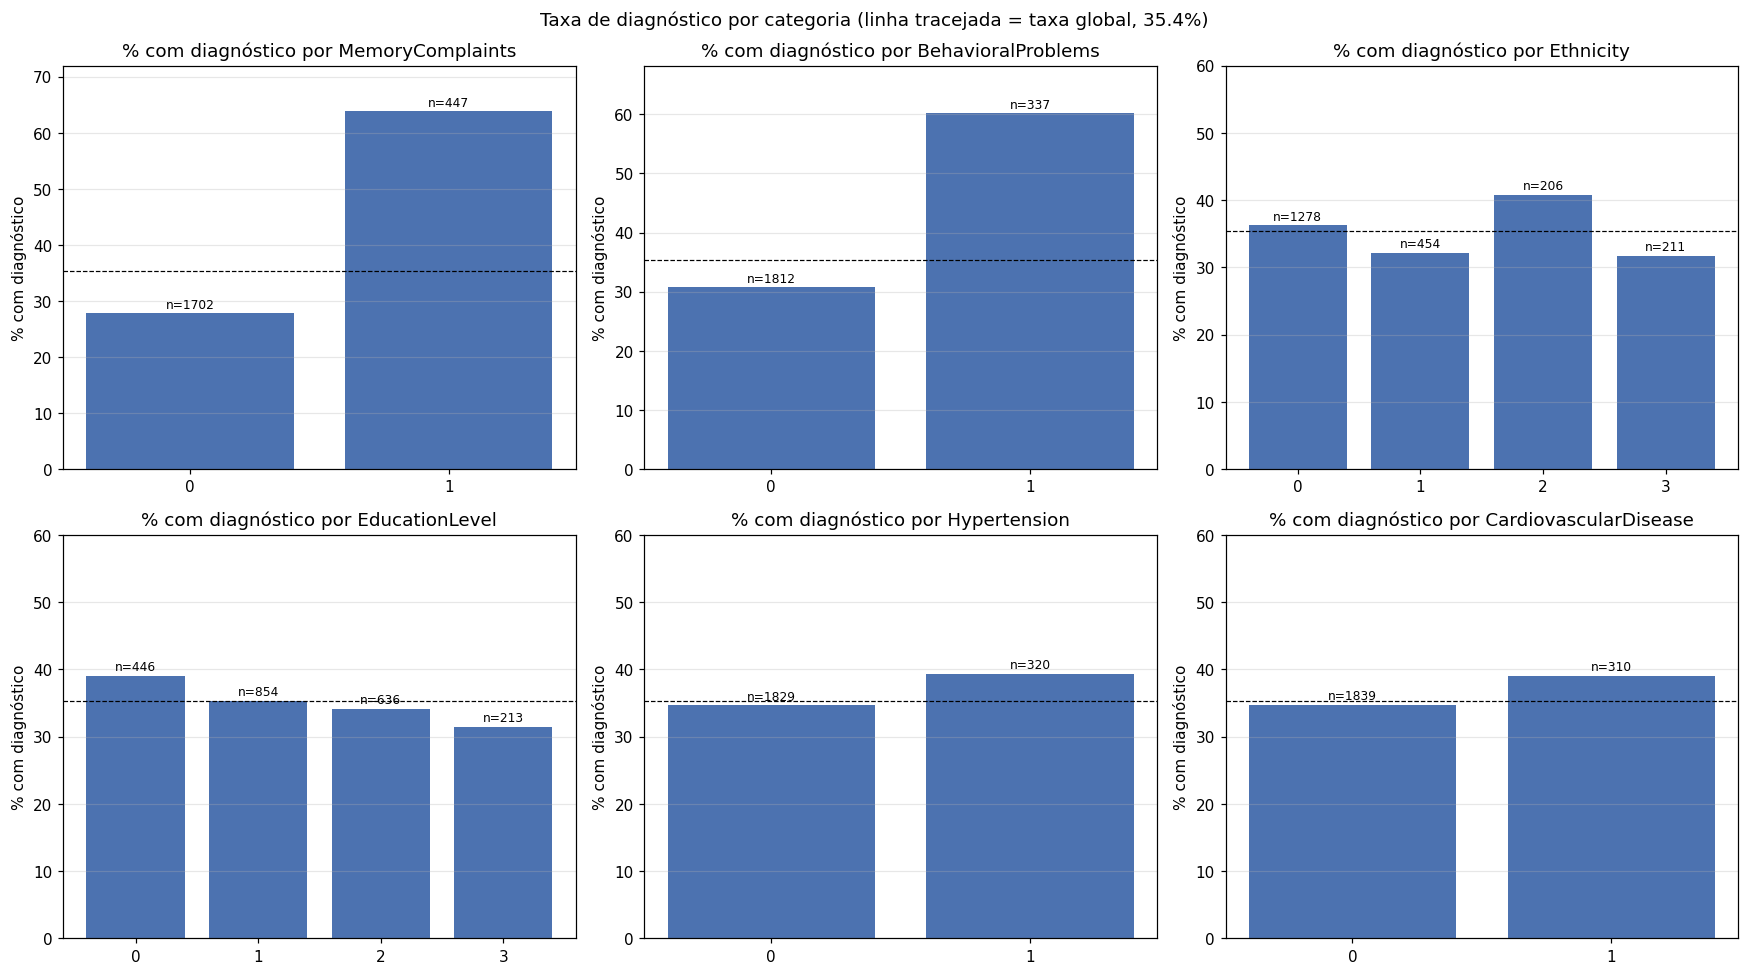

In [ ]:
from scipy.stats import chi2_contingency

alvo = "Diagnosis"

# categóricas = numéricas com poucos valores distintos (exclui PatientID, Age etc.)
todas_categoricas = [
    c for c in df.select_dtypes(include="number").columns
    if c != alvo and df[c].nunique() <= 5
]

taxa_global = df[alvo].mean() * 100
print(f"Taxa global de {alvo}: {taxa_global:.2f}%  (n = {len(df)})")
print("Resumo de Diagnosis (%) e tamanho amostral por categoria:")

resumos = {}
for col in todas_categoricas:
    r = (
        df.groupby(col)[alvo]
        .agg(n="count", diagnosticos="sum", taxa="mean")
        .assign(
            pct_base=lambda d: (d["n"] / len(df) * 100).round(2),
            taxa_diag_pct=lambda d: (d["taxa"] * 100).round(2),
        )
        .drop(columns="taxa")
    )
    resumos[col] = r
    print(f"\n--- {col} ---")
    display(r.sort_values("taxa_diag_pct", ascending=False))

# Ranking das categóricas: amplitude entre categorias + teste qui-quadrado
rank = []
for col in todas_categoricas:
    p = chi2_contingency(pd.crosstab(df[col], df[alvo]))[1]
    t = resumos[col]["taxa_diag_pct"]
    rank.append((col, t.max() - t.min(), p))
rank = (pd.DataFrame(rank, columns=["variavel", "amplitude_pp", "p_valor"])
          .sort_values("amplitude_pp", ascending=False).reset_index(drop=True))
print("\nRanking das categóricas (amplitude em pontos percentuais):")
display(rank.round(4))

# Painel: as 6 categóricas mais associadas
principais_cats = rank["variavel"].head(6).tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), principais_cats):
    d = resumos[col].sort_index()
    ax.bar(d.index.astype(str), d["taxa_diag_pct"], color="#4C72B0")
    ax.axhline(taxa_global, color="k", ls="--", lw=0.8)
    for i, (_, row) in enumerate(d.iterrows()):
        ax.text(i, row["taxa_diag_pct"] + 0.8, f"n={int(row['n'])}", ha="center", fontsize=8)
    ax.set_title(f"% com diagnóstico por {col}")
    ax.set_ylabel("% com diagnóstico")
    ax.set_ylim(0, max(60, d["taxa_diag_pct"].max() + 8))
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Taxa de diagnóstico por categoria (linha tracejada = taxa global, {taxa_global:.1f}%)")
plt.tight_layout()
plt.show()


## 3. Modelagem e Estratégia de Validação

* **Modelos principais:** Regressão Logística (linear), Random Forest (*bagging*) e XGBoost (*boosting*). A Árvore de Decisão será usada apenas nas etapas iniciais para a seleção de variaveis e para mostrar visualmente as regras do modelo.
* **Pré-processamento:** Padronização numérica com `StandardScaler` e codificação categórica com `OneHotEncoder`.
* **Estratégias de balanceamento:** Base Original, `Class Weight`, `SMOTE` e `Undersampling`.
* **Validação e ajuste:** Validação cruzada estratificada (`StratifiedKFold`) com seleção de hiperparâmetros via `GridSearchCV`.

In [ ]:
X_full = df.drop(columns=["Diagnosis"])
y = df["Diagnosis"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Treino: {X_train.shape} | Taxa de Alzheimer = {y_train.mean()*100:.2f}%")
print(f"Teste:  {X_test.shape} | Taxa de Alzheimer  = {y_test.mean()*100:.2f}%")

# Diagnóstico de colinearidade (VIF) exclusivamente no TREINO
# Diagnóstico de colinearidade (VIF) exclusivamente no TREINO
def calcular_vif(df_num: pd.DataFrame) -> pd.DataFrame:
    vifs = []
    for c in df_num.columns:
        X_outros = df_num.drop(columns=[c])
        r2 = LinearRegression().fit(X_outros, df_num[c]).score(X_outros, df_num[c])
        vif = np.inf if r2 >= 0.999999 else 1.0 / (1.0 - r2)
        vifs.append({"variavel": c, "R2_contra_outras": round(r2, 4), "VIF": round(vif, 2)})
    return pd.DataFrame(vifs).sort_values("VIF", ascending=False)

cols_num = [
    "Age", "BMI", "AlcoholConsumption", "PhysicalActivity",
    "DietQuality", "SleepQuality", "SystolicBP", "DiastolicBP",
    "CholesterolTotal", "CholesterolLDL", "CholesterolHDL",
    "CholesterolTriglycerides", "MMSE", "FunctionalAssessment", "ADL",
]

print("\nDiagnóstico VIF (Multicolinearidade Numérica no Treino):")
display(calcular_vif(X_train[cols_num]))

# Checagem de redundância nas colunas categóricas/binárias (constantes ou idênticas)
cols_cat = [c for c in X_train.columns if c not in cols_num]

constantes = [c for c in cols_cat if X_train[c].nunique() <= 1]
duplicadas = [
    (c1, c2)
    for i, c1 in enumerate(cols_cat)
    for c2 in cols_cat[i + 1:]
    if X_train[c1].equals(X_train[c2])
]

print(f"Colunas categóricas constantes no treino: {constantes}")
print(f"Pares de colunas categóricas 100% idênticas: {duplicadas}")


def preparar_representacao(df_in: pd.DataFrame, modo: str) -> pd.DataFrame:
    '''Transformação determinística linha a linha (sem uso de estatísticas globais).'''
    out = df_in.copy()

    # Garante que identificadores/constantes não entrem no modelo caso ainda estejam no df
    out = out.drop(columns=["PatientID", "DoctorInCharge"], errors="ignore")

    if modo == "1_Base_Completa":
        return out

    if modo == "2_Base_Reduzida":
        # Remove variáveis demográficas/clínicas de baixo sinal ou redundantes para testar um modelo mais enxuto
        cols_remover = ["Gender", "Ethnicity", "CholesterolTotal"]
        return out.drop(columns=cols_remover, errors="ignore")

    if modo == "3_Engenharia_Features":
        sintomas = [
            "MemoryComplaints", "BehavioralProblems", "Confusion",
            "Disorientation", "PersonalityChanges", "DifficultyCompletingTasks", "Forgetfulness",
        ]
        comorbidades = [
            "CardiovascularDisease", "Diabetes", "Depression",
            "HeadInjury", "Hypertension", "FamilyHistoryAlzheimers",
        ]

        # Compostos cognitivos e funcionais
        out["Cognitive_Functional_Index"] = (out["MMSE"] / 3.0) + out["FunctionalAssessment"] + out["ADL"]
        out["Func_x_ADL"] = out["FunctionalAssessment"] * out["ADL"]
        out["MMSE_baixo"] = (out["MMSE"] < 20).astype(int)

        # Carga de sintomas e comorbidades
        out["Total_Sintomas"] = out[sintomas].sum(axis=1)
        out["Sintomas_Chave"] = out["MemoryComplaints"] + out["BehavioralProblems"]
        out["Total_Comorbidades"] = out[comorbidades].sum(axis=1)

        # Razões clínicas (pressão e colesterol)
        out["Pulse_Pressure"] = out["SystolicBP"] - out["DiastolicBP"]
        out["LDL_HDL_Ratio"] = out["CholesterolLDL"] / np.maximum(out["CholesterolHDL"], 1e-5)

        return out.drop(columns=["Gender", "Ethnicity", "CholesterolTotal"], errors="ignore")

    raise ValueError(f"Modo desconhecido: {modo}")


def criar_preprocessador(df_exemplo: pd.DataFrame) -> ColumnTransformer:
    # Categórica nominal (só entra se estiver presente no modo atual)
    cat_c = [c for c in ["Ethnicity"] if c in df_exemplo.columns]

    # Binárias (0/1) — não precisam de scaling nem de OHE
    bin_c = [
        c for c in df_exemplo.columns
        if c not in cat_c and df_exemplo[c].nunique() <= 2
    ]


    num_c = [c for c in df_exemplo.columns if c not in cat_c and c not in bin_c]

    transformers = [
        ("num", StandardScaler(), num_c),
        ("bin", "passthrough", bin_c),
    ]
    if cat_c:
        transformers.append(
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_c)
        )

    return ColumnTransformer(
        transformers=transformers,
        verbose_feature_names_out=False,
    )


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ablation_rows = []

for modo in ["1_Base_Completa", "2_Base_Reduzida", "3_Engenharia_Features"]:
    X_var = preparar_representacao(X_train, modo)
    prep_var = criar_preprocessador(X_var)
    n_pos_ohe = clone(prep_var).fit(X_var).transform(X_var.iloc[:1]).shape[1]

    for nome_clf, clf in [
        ("LogisticRegression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        ("DecisionTree", DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE)),
        ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1)),
        ("XGBoost", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
    ]:
        pipe_var = ImbPipeline([("prep", clone(prep_var)), ("clf", clf)])
        cv_out = cross_validate(
            pipe_var, X_var, y_train, cv=cv,
            scoring={"roc_auc": "roc_auc", "ap": "average_precision"}, n_jobs=-1
        )
        ablation_rows.append({
            "Representacao": modo,
            "Modelo": nome_clf,
            "Dimensao_Pos_OHE": int(n_pos_ohe),
            "CV_ROC_AUC_Mean": cv_out["test_roc_auc"].mean(),
            "CV_ROC_AUC_Std": cv_out["test_roc_auc"].std(),
            "CV_AP_Mean": cv_out["test_ap"].mean(),
            "CV_AP_Std": cv_out["test_ap"].std(),
        })

ablation_df = pd.DataFrame(ablation_rows).sort_values(["Modelo", "CV_AP_Mean"], ascending=[True, False])
print("\nResultado em CV (5 folds) — Impacto de Remoção de Redundâncias e Engenharia:")
display(ablation_df.round(4))

# Seleção estritamente guiada pela média CV Average Precision no conjunto de treino (zero leakage)
resumo_modos = ablation_df.groupby("Representacao")["CV_AP_Mean"].mean().sort_values(ascending=False)
MODO_ESCOLHIDO = resumo_modos.index[0]
print(f"\nRepresentação com maior Average Precision médio em CV: {MODO_ESCOLHIDO}")

Treino: (1719, 32) | Taxa de Alzeihmner = 35.37%
Teste:  (430, 32) | Taxa de Alzeihmner  = 35.35%

Diagnóstico VIF (Multicolinearidade Numérica no Treino):


,variavel,R2_contra_outras,VIF
0,Age,0.0060,1.01
1,BMI,0.0064,1.01
2,AlcoholConsumption,0.0075,1.01
4,DietQuality,0.0083,1.01
5,SleepQuality,0.0090,1.01
6,SystolicBP,0.0089,1.01
10,CholesterolHDL,0.0056,1.01
13,FunctionalAssessment,0.0120,1.01
9,CholesterolLDL,0.0098,1.01
12,MMSE,0.0071,1.01


Colunas categóricas constantes no treino: []
Pares de colunas categóricas 100% idênticas: []

Resultado em CV (5 folds) — Impacto de Remoção de Redundâncias e Engenharia:


,Representacao,Modelo,Dimensao_Pos_OHE,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_AP_Mean,CV_AP_Std
5,2_Base_Reduzida,DecisionTree,29,0.9567,0.0103,0.9263,0.0137
1,1_Base_Completa,DecisionTree,34,0.9556,0.0111,0.9216,0.0206
9,3_Engenharia_Features,DecisionTree,37,0.9380,0.0173,0.9009,0.0331
8,3_Engenharia_Features,LogisticRegression,37,0.9109,0.0151,0.8604,0.0296
4,2_Base_Reduzida,LogisticRegression,29,0.9054,0.0137,0.8489,0.0281
0,1_Base_Completa,LogisticRegression,34,0.9034,0.0130,0.8473,0.0270
6,2_Base_Reduzida,RandomForest,29,0.9563,0.0124,0.9371,0.0194
2,1_Base_Completa,RandomForest,34,0.9542,0.0128,0.9371,0.0177
10,3_Engenharia_Features,RandomForest,37,0.9554,0.0107,0.9334,0.0191
3,1_Base_Completa,XGBoost,34,0.9572,0.0120,0.9442,0.0186



Representação com maior Average Precision médio em CV: 2_Base_Reduzida


* Pois ao criar variaveis novas e ao usar a base completa de dados em média não muda muito, optei por usar a base de dados reduzida para fins de simplificar o modelo.

### Visualização das Regras de Decisão

Abaixo, ajustamos uma **Árvore de Decisão** com profundidade limitada (`max_depth=3`) sobre a base reduzida de treino apenas para fins de interpretabilidade, permitindo observar visualmente quais variáveis e pontos de corte mais separam os grupos de diagnóstico.

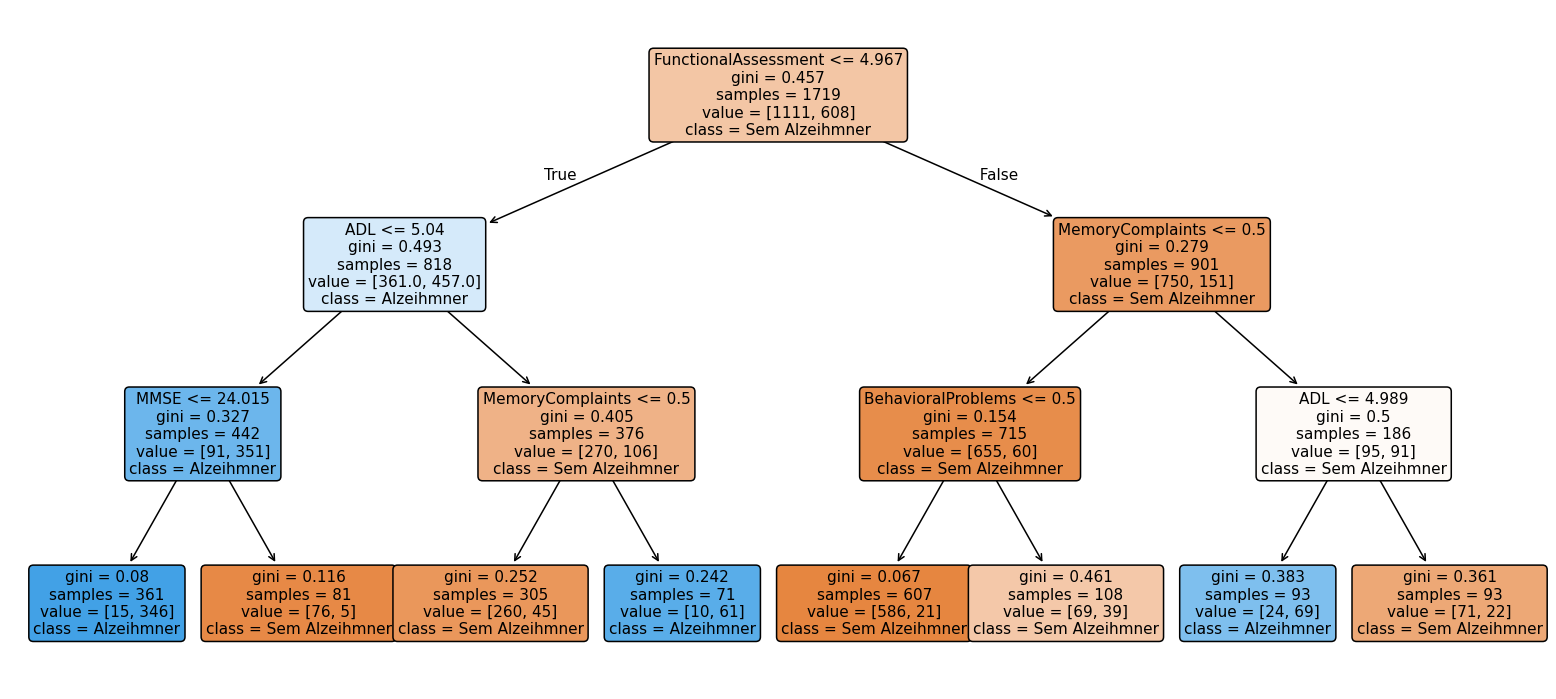

In [ ]:
MODO_ESCOLHIDO="2_Base_Reduzida"

from sklearn.tree import plot_tree

X_plot = preparar_representacao(X_train, "2_Base_Reduzida")
prep_plot = criar_preprocessador(X_plot)
X_plot_t = prep_plot.fit_transform(X_plot)



dt_real = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE)
dt_real.fit(X_plot, y_train)

plt.figure(figsize=(18, 8))
plot_tree(
    dt_real,
    feature_names=X_plot.columns,
    class_names=["Sem Alzheimer (0)", "Com Alzheimer (1)"],
    filled=True, rounded=True, fontsize=10
)
plt.show()

* As Principais variaveis que aparecem no topo da  arvore de decisão para classificar são "FunctionalAssessment" e  "ADL" e "MemoryComplaints"

### Controle de Overfitting

Para prevenir o *overfitting*, a complexidade dos modelos foi controlada (por meio de hiperparâmetros como regularização e profundidade máxima) para evitar que os algoritmos apenas decorem os dados de treino, utilizando `GridSearchCV` dentro de um pipeline sem vazamento de dados (*data leakage*).

A ocorrência de *overfitting* é verificada comparando o desempenho no conjunto de teste com o obtido na validação cruzada: caso a nota no teste caia de forma acentuada em relação à validação cruzada, há indício de sobreajuste.

### Escolha dos hiperparâmetros usando GridSearchCV

In [ ]:
X_tr_mod = preparar_representacao(X_train, MODO_ESCOLHIDO)
X_te_mod = preparar_representacao(X_test, MODO_ESCOLHIDO)
preprocessador = criar_preprocessador(X_tr_mod)

# Razão de desbalanceamento calculada exclusivamente no conjunto de treino
scale_pos = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Fator scale_pos_weight (y_train): {scale_pos:.4f} | Representação ativa: {MODO_ESCOLHIDO}")

estrategias = {
    "1_Original": None,
    "2_Class_Weight": "class_weight",
    "3_SMOTE": SMOTE(random_state=RANDOM_STATE),
    "4_Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
}

modelos_grids = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [200, 300], "clf__max_depth": [6, 10, 14]},
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [150, 250], "clf__max_depth": [3, 5], "clf__learning_rate": [0.05, 0.1]},
    ),
}

resultados = []
melhores_pipelines = {}

for est_nome, est_obj in estrategias.items():
    for mod_nome, (mod_base, grid) in modelos_grids.items():
        clf = clone(mod_base)
        sampler_step = "passthrough"

        if est_obj == "class_weight":
            if mod_nome == "XGBoost":
                clf.set_params(scale_pos_weight=scale_pos)
            else:
                clf.set_params(class_weight="balanced")
        elif est_obj is not None:
            sampler_step = clone(est_obj)

        pipe = ImbPipeline([
            ("prep", clone(preprocessador)),
            ("sampler", sampler_step),
            ("clf", clf),
        ])

        gs = GridSearchCV(
            estimator=pipe,
            param_grid=grid,
            cv=cv,
            scoring="average_precision",
            n_jobs=-1,
        )
        gs.fit(X_tr_mod, y_train)

        best_pipe = gs.best_estimator_
        melhores_pipelines[(est_nome, mod_nome)] = best_pipe

        y_pred = best_pipe.predict(X_te_mod)
        y_prob = best_pipe.predict_proba(X_te_mod)[:, 1]

        resultados.append({
            "Estrategia": est_nome,
            "Modelo": mod_nome,
            "Melhores_Params": gs.best_params_,
            "CV_AP": gs.best_score_,
            "Test_Precision": precision_score(y_test, y_pred, zero_division=0),
            "Test_Recall": recall_score(y_test, y_pred),
            "Test_F1": f1_score(y_test, y_pred),
            "Test_ROC_AUC": roc_auc_score(y_test, y_prob),
            "Test_AP": average_precision_score(y_test, y_prob),
        })

df_resultados = (
    pd.DataFrame(resultados)
    .sort_values(["Test_AP", "Test_ROC_AUC"], ascending=False)
    .reset_index(drop=True)
)
print("\nTabela Comparativa Geral no Conjunto de Teste (ordenada por Test_AP):")
display(df_resultados.drop(columns=["Melhores_Params"]).round(4))

print("\nMelhores Hiperparâmetros (selecionados exclusivamente em CV):")
for _, row in df_resultados.iterrows():
    print(f" - {row['Estrategia']:16s} | {row['Modelo']:18s} -> {row['Melhores_Params']}")

Fator scale_pos_weight (y_train): 1.8273 | Representação ativa: 2_Base_Reduzida

Tabela Comparativa Geral no Conjunto de Teste (ordenada por Test_AP):


,Estrategia,Modelo,CV_AP,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Test_AP
0,2_Class_Weight,XGBoost,0.9433,0.9267,0.9145,0.9205,0.9465,0.9379
1,4_Undersampling,XGBoost,0.9400,0.9216,0.9276,0.9246,0.9459,0.9373
2,1_Original,XGBoost,0.9454,0.9329,0.9145,0.9236,0.9448,0.9368
3,3_SMOTE,XGBoost,0.9437,0.9211,0.9211,0.9211,0.9416,0.9344
4,3_SMOTE,RandomForest,0.9362,0.9452,0.9079,0.9262,0.9409,0.9255
5,2_Class_Weight,RandomForest,0.9349,0.9448,0.9013,0.9226,0.9408,0.9249
6,1_Original,RandomForest,0.9390,0.9444,0.8947,0.9189,0.9398,0.9220
7,4_Undersampling,RandomForest,0.9370,0.9400,0.9276,0.9338,0.9462,0.9218
8,4_Undersampling,LogisticRegression,0.8481,0.6978,0.8355,0.7605,0.8915,0.8432
9,1_Original,LogisticRegression,0.8503,0.7857,0.7237,0.7534,0.8901,0.8393



Melhores Hiperparâmetros (selecionados exclusivamente em CV):
 - 2_Class_Weight   | XGBoost            -> {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 4_Undersampling  | XGBoost            -> {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 250}
 - 1_Original       | XGBoost            -> {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 3_SMOTE          | XGBoost            -> {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 150}
 - 3_SMOTE          | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 300}
 - 2_Class_Weight   | RandomForest       -> {'clf__max_depth': 10, 'clf__n_estimators': 200}
 - 1_Original       | RandomForest       -> {'clf__max_depth': 10, 'clf__n_estimators': 200}
 - 4_Undersampling  | RandomForest       -> {'clf__max_depth': 6, 'clf__n_estimators': 300}
 - 4_Undersampling  | LogisticRegression -> {'clf__C': 0.1}
 - 1_Original       | Logistic

### Impacto das Estratégias de Balanceamento ($\Delta$ em relação à Base Original)

A tabela abaixo mostra a variação ($\Delta$) de cada **métrica de desempenho no teste** ao aplicar as estratégias de balanceamento em comparação com o modelo treinado na **base original** (valores positivos indicam ganho e negativos indicam queda).

In [ ]:
base = df_resultados[df_resultados["Estrategia"] == "1_Original"].set_index("Modelo")
metricas = ["Test_Precision", "Test_Recall", "Test_F1", "Test_ROC_AUC", "Test_AP"]
linhas = []
for _, r in df_resultados[df_resultados["Estrategia"] != "1_Original"].iterrows():
 d = {"Modelo": r["Modelo"], "Estrategia": r["Estrategia"]}
 for m in metricas:
  d["Δ " + m.replace("Test_", "")] = r[m] - base.loc[r["Modelo"], m]
 linhas.append(d)
df_delta = pd.DataFrame(linhas).sort_values(["Modelo", "Estrategia"]).reset_index(drop=True)
print("Diferença em relação ao treinamento com a distribuição original (positivo = melhora):")
display(df_delta.round(4))

Diferença em relação ao treinamento com a distribuição original (positivo = melhora):


,Modelo,Estrategia,Δ Precision,Δ Recall,Δ F1,Δ ROC_AUC,Δ AP
0,LogisticRegression,2_Class_Weight,-0.0959,0.1250,0.0076,-0.0016,-0.0053
1,LogisticRegression,3_SMOTE,-0.0863,0.1184,0.0108,-0.0012,-0.0051
2,LogisticRegression,4_Undersampling,-0.0879,0.1118,0.0071,0.0015,0.0040
3,RandomForest,2_Class_Weight,0.0004,0.0066,0.0036,0.0009,0.0030
4,RandomForest,3_SMOTE,0.0008,0.0132,0.0073,0.0011,0.0035
5,RandomForest,4_Undersampling,-0.0044,0.0329,0.0149,0.0063,-0.0002
6,XGBoost,2_Class_Weight,-0.0062,0.0000,-0.0031,0.0018,0.0010
7,XGBoost,3_SMOTE,-0.0118,0.0066,-0.0025,-0.0031,-0.0025
8,XGBoost,4_Undersampling,-0.0113,0.0132,0.0010,0.0012,0.0005


In [ ]:
best_row_ap = df_resultados.iloc[0]
best_est_ap = best_row_ap["Estrategia"]
best_mod_ap = best_row_ap["Modelo"]
best_pipe_ap = melhores_pipelines[(best_est_ap, best_mod_ap)]
best_row_f1 = df_resultados.sort_values("Test_F1", ascending=False).iloc[0]
best_est_f1 = best_row_f1["Estrategia"]
best_mod_f1 = best_row_f1["Modelo"]
print(f"Campeão em ordenação probabilística (Test_AP): {best_mod_ap} | {best_est_ap} (AP={best_row_ap['Test_AP']:.4f}, AUC={best_row_ap['Test_ROC_AUC']:.4f})")
print(f"Campeão em equilíbrio F1 (limiar 0.50): {best_mod_f1} | {best_est_f1} (F1={best_row_f1['Test_F1']:.4f}, Recall={best_row_f1['Test_Recall']:.4f})")

Campeão em ordenação probabilística (Test_AP): XGBoost | 2_Class_Weight (AP=0.9379, AUC=0.9465)
Campeão em equilíbrio F1 (limiar 0.50): RandomForest | 4_Undersampling (F1=0.9338, Recall=0.9276)


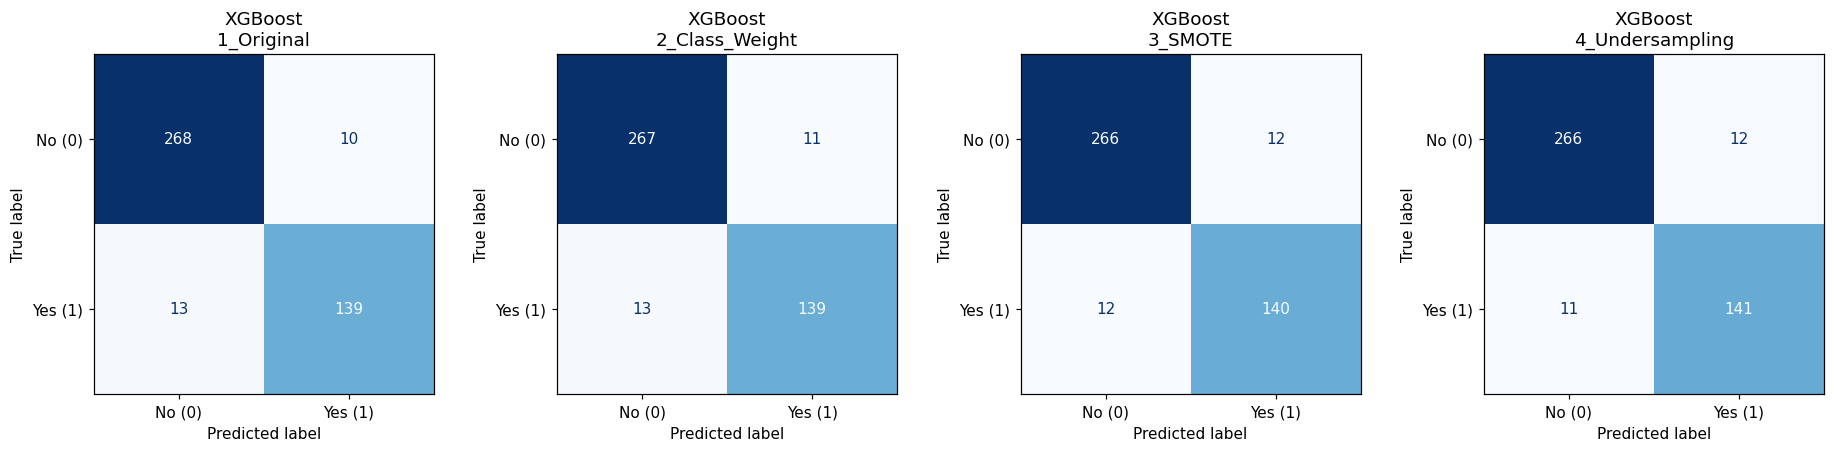


Relatório de Classificação Detalhado — RandomForest (4_Undersampling):
                  precision    recall  f1-score   support

No Alzeihmer (0)       0.96      0.97      0.96       278
   Alzeihmer (1)       0.94      0.93      0.93       152

        accuracy                           0.95       430
       macro avg       0.95      0.95      0.95       430
    weighted avg       0.95      0.95      0.95       430



In [ ]:
# 6.1 Matrizes de Confusão das 4 estratégias no algoritmo vencedor em AP
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, est_nome in zip(axes, estrategias.keys()):
    pipe_e = melhores_pipelines[(est_nome, best_mod_ap)]
    cm = confusion_matrix(y_test, pipe_e.predict(X_te_mod))
    ConfusionMatrixDisplay(cm, display_labels=["No (0)", "Yes (1)"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{best_mod_ap}\n{est_nome}")
plt.tight_layout()
plt.show()

print(f"\nRelatório de Classificação Detalhado — {best_mod_f1} ({best_est_f1}):")
print(classification_report(
    y_test,
    melhores_pipelines[(best_est_f1, best_mod_f1)].predict(X_te_mod),
    target_names=["Sem Alzheimer (0)", "Com Alzheimer (1)"],
))

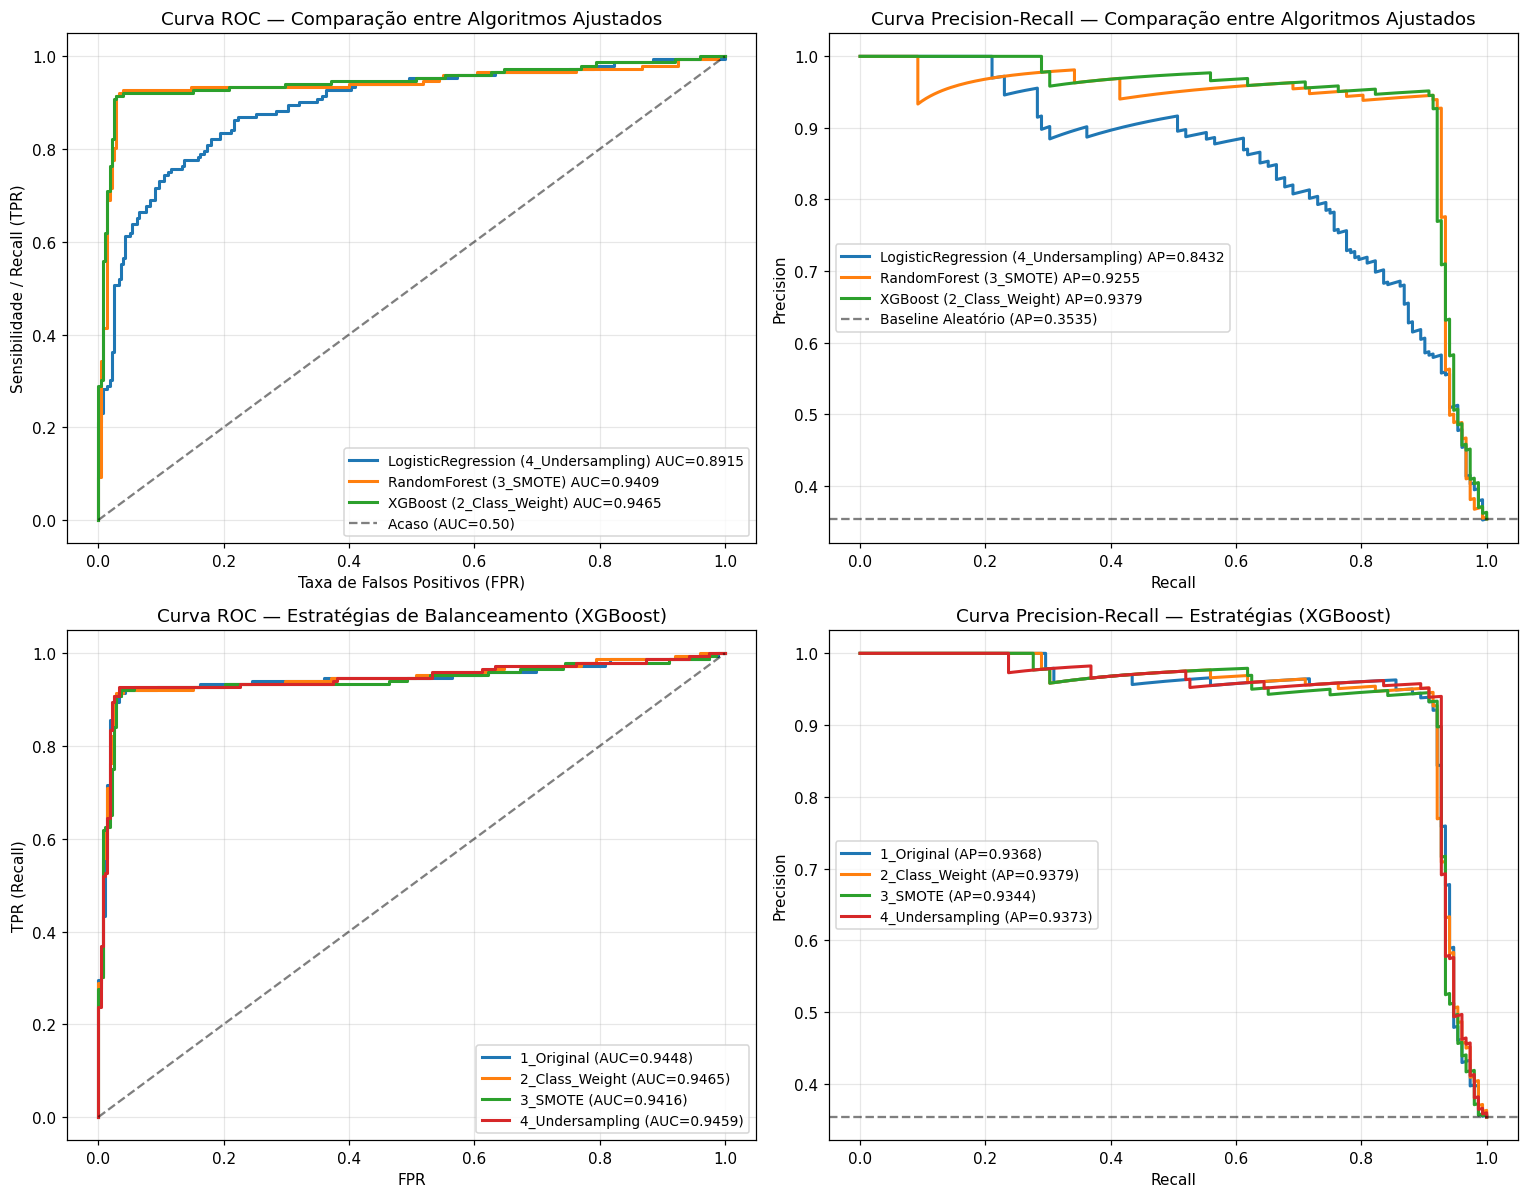

In [ ]:
# 6.2 Curvas ROC & PR: (A) Melhor de cada algoritmo vs. (B) 4 estratégias no algoritmo campeão
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
prevalencia_teste = y_test.mean()

# Linha superior: comparação entre algoritmos
for mod_nome in ["LogisticRegression", "RandomForest", "XGBoost"]:
    sub = df_resultados[df_resultados["Modelo"] == mod_nome].iloc[0]
    y_p = melhores_pipelines[(sub["Estrategia"], mod_nome)].predict_proba(X_te_mod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_p)
    axes[0, 0].plot(fpr, tpr, lw=2, label=f"{mod_nome} ({sub['Estrategia']}) AUC={sub['Test_ROC_AUC']:.4f}")
    axes[0, 1].plot(rec_c, prec_c, lw=2, label=f"{mod_nome} ({sub['Estrategia']}) AP={sub['Test_AP']:.4f}")

axes[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Acaso (AUC=0.50)")
axes[0, 0].set_title("Curva ROC — Comparação entre Algoritmos Ajustados")
axes[0, 0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0, 0].set_ylabel("Sensibilidade / Recall (TPR)")
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(alpha=0.3)

axes[0, 1].axhline(prevalencia_teste, color="k", ls="--", alpha=0.5, label=f"Baseline Aleatório (AP={prevalencia_teste:.4f})")
axes[0, 1].set_title("Curva Precision-Recall — Comparação entre Algoritmos Ajustados")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(alpha=0.3)

# Linha inferior: comparação entre estratégias de balanceamento no melhor algoritmo
for est_nome in estrategias.keys():
    sub_e = df_resultados[(df_resultados["Modelo"] == best_mod_ap) & (df_resultados["Estrategia"] == est_nome)].iloc[0]
    y_p = melhores_pipelines[(est_nome, best_mod_ap)].predict_proba(X_te_mod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_p)
    axes[1, 0].plot(fpr, tpr, lw=2, label=f"{est_nome} (AUC={sub_e['Test_ROC_AUC']:.4f})")
    axes[1, 1].plot(rec_c, prec_c, lw=2, label=f"{est_nome} (AP={sub_e['Test_AP']:.4f})")

axes[1, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1, 0].set_title(f"Curva ROC — Estratégias de Balanceamento ({best_mod_ap})")
axes[1, 0].set_xlabel("FPR")
axes[1, 0].set_ylabel("TPR (Recall)")
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(alpha=0.3)

axes[1, 1].axhline(prevalencia_teste, color="k", ls="--", alpha=0.5)
axes[1, 1].set_title(f"Curva Precision-Recall — Estratégias ({best_mod_ap})")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3.1 Ajuste do Limiar de Decisão (Base Original)

Variação do Limiar de Decisão — XGBoost (1_Original):


,Limiar,Clientes_Acionados,Pct_Base_Acionada,Precision,Recall,F1
0,0.15,184,42.79,0.7663,0.9276,0.8393
1,0.20,166,38.60,0.8434,0.9211,0.8805
2,0.25,158,36.74,0.8861,0.9211,0.9032
3,0.30,156,36.28,0.8974,0.9211,0.9091
4,0.35,154,35.81,0.9091,0.9211,0.9150
5,0.40,153,35.58,0.9150,0.9211,0.9180
6,0.45,150,34.88,0.9267,0.9145,0.9205
7,0.50,149,34.65,0.9329,0.9145,0.9236
8,0.55,149,34.65,0.9329,0.9145,0.9236
9,0.60,148,34.42,0.9324,0.9079,0.9200


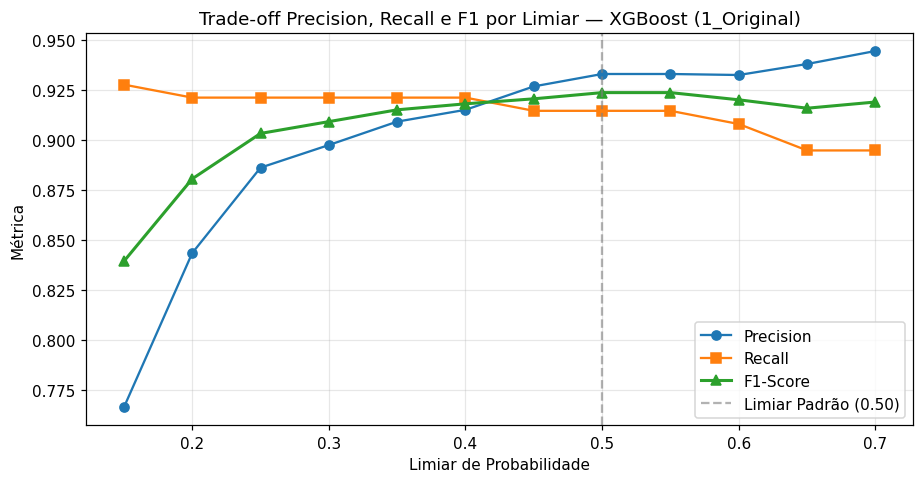

In [ ]:

pipe_orig_campeao = melhores_pipelines[("1_Original", best_mod_ap)]
y_prob_orig_campeao = pipe_orig_campeao.predict_proba(X_te_mod)[:, 1]
limiares = np.round(np.arange(0.15, 0.75, 0.05), 2)
linhas_limiar = []
for th in limiares:
 yp = (y_prob_orig_campeao >= th).astype(int)
 linhas_limiar.append({
 "Limiar": float(th),
 "Pacientes_Sinalizados": int(yp.sum()),
 "Pct_Base_Sinalizada": round(yp.mean() * 100, 2),
 "Precision": round(precision_score(y_test, yp, zero_division=0), 4),
 "Recall": round(recall_score(y_test, yp), 4),
 "F1": round(f1_score(y_test, yp), 4),
 })
df_limiares = pd.DataFrame(linhas_limiar)
print(f"Variação do Limiar de Decisão — {best_mod_ap} (1_Original):")
display(df_limiares)
plt.figure(figsize=(8.5, 4.5))
plt.plot(df_limiares["Limiar"], df_limiares["Precision"], "o-", label="Precision")
plt.plot(df_limiares["Limiar"], df_limiares["Recall"], "s-", label="Recall")
plt.plot(df_limiares["Limiar"], df_limiares["F1"], "^-", lw=2, label="F1-Score")
plt.axvline(0.50, color="gray", ls="--", alpha=0.6, label="Limiar Padrão (0.50)")
plt.title(f"Trade-off Precision, Recall e F1 por Limiar — {best_mod_ap} (1_Original)")
plt.xlabel("Limiar de Probabilidade")
plt.ylabel("Métrica")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import cross_val_predict

pipe_limiar = clone(melhores_pipelines[("1_Original", best_mod_ap)])
oof_prob = cross_val_predict(pipe_limiar, X_tr_mod, y_train, cv=cv, method="predict_proba")[:, 1]

grid_lim = np.round(np.arange(0.15, 0.75, 0.05), 2)
oof_f1 = [f1_score(y_train, (oof_prob >= t).astype(int)) for t in grid_lim]
limiar_cv = float(grid_lim[int(np.argmax(oof_f1))])

yp_cv = (y_prob_orig_campeao >= limiar_cv).astype(int)
yp_50 = (y_prob_orig_campeao >= 0.50).astype(int)
tab_lim_cv = pd.DataFrame({
    "Limiar": [0.50, limiar_cv],
    "Origem do limiar": ["padrão", "maximiza F1 em CV (treino)"],
    "Precision": [precision_score(y_test, yp_50), precision_score(y_test, yp_cv)],
    "Recall": [recall_score(y_test, yp_50), recall_score(y_test, yp_cv)],
    "F1": [f1_score(y_test, yp_50), f1_score(y_test, yp_cv)],
    "Pacientes_Sinalizados": [int(yp_50.sum()), int(yp_cv.sum())],
})
print(f"Limiar escolhido apenas com dados de treino (out-of-fold): {limiar_cv:.2f}")
print("Desempenho no TESTE com esse limiar vs. o limiar padrão:")
display(tab_lim_cv.round(4))

Limiar escolhido apenas com dados de treino (out-of-fold): 0.50
Desempenho no TESTE com esse limiar vs. o limiar padrão:


,Limiar,Origem do limiar,Precision,Recall,F1,Clientes_Acionados
0,0.5,padrão,0.9329,0.9145,0.9236,149
1,0.5,maximiza F1 em CV (treino),0.9329,0.9145,0.9236,149


### 3.2 Importância das Variáveis e Síntese dos Resultados

Para analisar a importância das variáveis, será utilizada a **base original**, sem aplicação de técnicas de reamostragem. Essa escolha tem três motivos principais:

- **Fidelidade à distribuição real:** preserva o comportamento original dos dados, evitando distorções causadas por amostras sintéticas (SMOTE) ou descarte de registros (Undersampling).
- **Comparação justa:** garante que todos os modelos sejam avaliados sob as mesmas condições, sem que algum algoritmo seja favorecido ou prejudicado por uma estratégia específica de reamostragem.
- **Desbalanceamento moderado:** como a taxa de diagnóstico positivo é de aproximadamente **35%**, os dados não são extremamente desbalanceados, permitindo que os modelos aprendam e identifiquem padrões relevantes diretamente na distribuição original.

Consistência de Importância Relativa (%) entre os 3 Modelos (Top 12 atributos):


,LR_Coef_Direcional,LR_Imp_%,RF_Imp_%,XGB_Imp_%,Media_Imp_%
MemoryComplaints,1.9805,23.43,10.58,15.55,16.52
FunctionalAssessment,-1.0610,12.55,19.43,14.87,15.62
ADL,-1.0228,12.10,18.90,14.92,15.31
BehavioralProblems,1.6952,20.06,5.22,9.88,11.72
MMSE,-0.6970,8.25,13.36,12.30,11.30
CholesterolHDL,0.1332,1.58,2.72,2.07,2.12
CholesterolTriglycerides,0.0958,1.13,2.80,2.20,2.04
SleepQuality,-0.0993,1.17,2.71,2.12,2.00
CholesterolLDL,-0.1160,1.37,2.46,2.14,1.99
Age,-0.1060,1.25,2.04,2.07,1.79


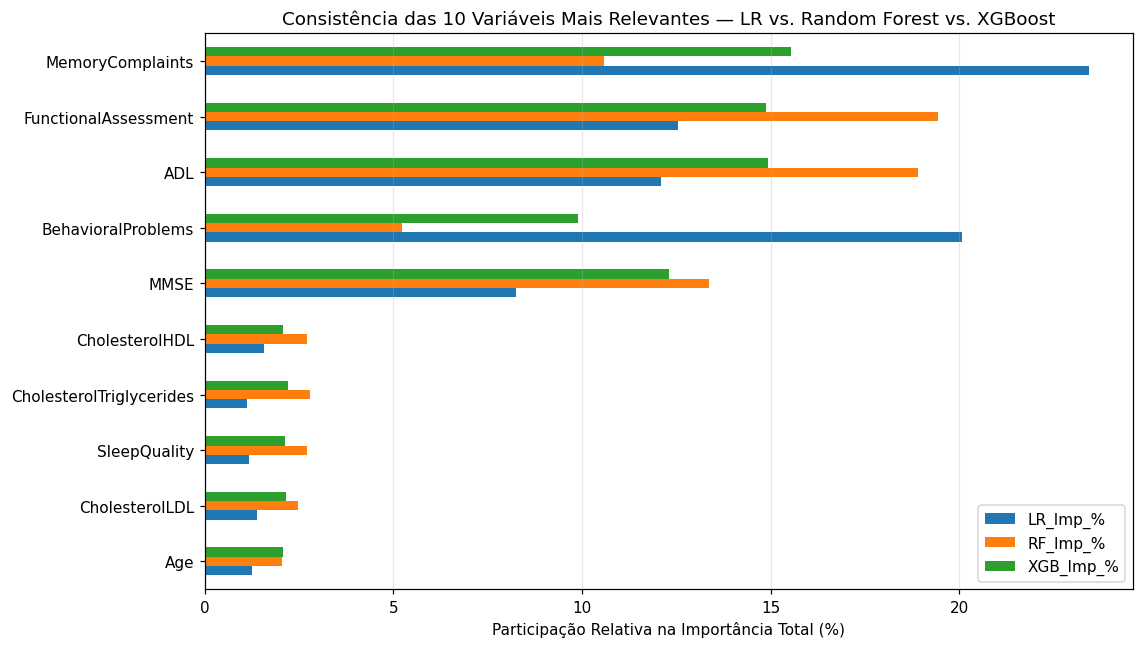

SÍNTESE QUANTITATIVA AUTOMÁTICA PARA AS QUESTÕES DO PROJETO
1) Top 5 atributos consensuais (média %): ['MemoryComplaints', 'FunctionalAssessment', 'ADL', 'BehavioralProblems', 'MMSE']
2) Melhor ranking global (Test_AP):     XGBoost | 2_Class_Weight (AP=0.9379, AUC=0.9465)
3) Melhor F1 no limiar padrão 0.50:     RandomForest | 4_Undersampling (F1=0.9338, Recall=0.9276)
4) Melhor F1 por ajuste de limiar (XGBoost 1_Original): limiar=0.55 -> F1=0.9236, Recall=0.9145, Prec=0.9329


In [ ]:
def extrair_importancias_norm(pipe_treinado: ImbPipeline, modelo_nome: str) -> pd.Series:
    nomes = pipe_treinado.named_steps["prep"].get_feature_names_out()
    clf = pipe_treinado.named_steps["clf"]
    vals = np.abs(clf.coef_[0]) if modelo_nome == "LogisticRegression" else clf.feature_importances_
    s = pd.Series(vals, index=nomes)
    return (s / s.sum()) * 100.0

imp_lr = extrair_importancias_norm(melhores_pipelines[("1_Original", "LogisticRegression")], "LogisticRegression")
imp_rf = extrair_importancias_norm(melhores_pipelines[("1_Original", "RandomForest")], "RandomForest")
imp_xgb = extrair_importancias_norm(melhores_pipelines[("1_Original", "XGBoost")], "XGBoost")

nomes_feat = melhores_pipelines[("1_Original", "LogisticRegression")].named_steps["prep"].get_feature_names_out()
coefs_lr = pd.Series(
    melhores_pipelines[("1_Original", "LogisticRegression")].named_steps["clf"].coef_[0],
    index=nomes_feat,
)

df_imp = pd.DataFrame({
    "LR_Coef_Direcional": coefs_lr.round(4),
    "LR_Imp_%": imp_lr.round(2),
    "RF_Imp_%": imp_rf.round(2),
    "XGB_Imp_%": imp_xgb.round(2),
})
df_imp["Media_Imp_%"] = df_imp[["LR_Imp_%", "RF_Imp_%", "XGB_Imp_%"]].mean(axis=1).round(2)
df_imp = df_imp.sort_values("Media_Imp_%", ascending=False)

print("Consistência de Importância Relativa (%) entre os 3 Modelos (Top 12 atributos):")
display(df_imp.head(12))

top10_plot = df_imp.head(10).sort_values("Media_Imp_%", ascending=True)
top10_plot[["LR_Imp_%", "RF_Imp_%", "XGB_Imp_%"]].plot(kind="barh", figsize=(10.5, 6))
plt.title("Consistência das 10 Variáveis Mais Relevantes — LR vs. Random Forest vs. XGBoost")
plt.xlabel("Participação Relativa na Importância Total (%)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

limiar_max_f1 = df_limiares.sort_values("F1", ascending=False).iloc[0]
print("=" * 72)
print("SÍNTESE QUANTITATIVA AUTOMÁTICA PARA AS QUESTÕES DO PROJETO")
print("=" * 72)
print(f"1) Top 5 atributos consensuais (média %): {list(df_imp.head(5).index)}")
print(f"2) Melhor ranking global (Test_AP):     {best_mod_ap} | {best_est_ap} (AP={best_row_ap['Test_AP']:.4f}, AUC={best_row_ap['Test_ROC_AUC']:.4f})")
print(f"3) Melhor F1 no limiar padrão 0.50:     {best_mod_f1} | {best_est_f1} (F1={best_row_f1['Test_F1']:.4f}, Recall={best_row_f1['Test_Recall']:.4f})")
print(f"4) Melhor F1 por ajuste de limiar ({best_mod_ap} 1_Original): limiar={limiar_max_f1['Limiar']:.2f} -> F1={limiar_max_f1['F1']:.4f}, Recall={limiar_max_f1['Recall']:.4f}, Prec={limiar_max_f1['Precision']:.4f}")




## 4. Discussão Crítica

- De acordo com os modelos, as variáveis mais importantes são: `MemoryComplaints`, `FunctionalAssessment`, `ADL`, `BehavioralProblems` e `MMSE`. Isso confirma a hipótese inicial **$H_1$**, de que fatores cognitivos, funcionais e comportamentais possuem forte associação com o diagnóstico.

- Quanto à hipótese **$H_2$**, ela não é necessariamente descartada do ponto de vista clínico, mas **não se confirmou como fator relevante nesta base de dados**: variáveis demográficas, histórico familiar e hábitos de vida (como idade, IMC e qualidade do sono) tiveram contribuição apenas secundária nos modelos, ficando em segundo plano frente aos indicadores cognitivos, funcionais e comportamentais.

- É importante ressaltar que a relevância atribuída às variáveis pelos modelos indica apenas **associação estatística**, e não **causalidade**. Portanto, para um diagnóstico preciso, os modelos devem atuar apenas como apoio à triagem, sendo indispensável a avaliação de especialistas da área para validar clinicamente os resultados.

## Resposta à Questão Fundamental

**Sim, é possível prever o diagnóstico da Doença de Alzheimer** com bom desempenho a partir dos atributos clínicos, cognitivos e funcionais presentes na base.

Como recomendação prática para triagem, uma estratégia promissora é combinar os dois modelos com melhor desempenho (**XGBoost** e **Random Forest**) por meio da média de suas probabilidades (*ensemble*). Quando ambos concordam na classificação, a confiança na triagem é maior; já nos casos em que há divergência entre os modelos, o paciente deve ser sinalizado para avaliação prioritária por um especialista, permitindo que um modelo ajude a capturar padrões que o outro não identificou.

## 5. Sumário do Projeto

Neste projeto, abordamos a predição da Doença de Alzheimer como um problema de **classificação supervisionada binária** (2.149 pacientes). O fluxo iniciou com a preparação, limpeza e análise estatística exploratória dos dados, seguido pela divisão estratificada em conjuntos de treino e teste (80/20).

Na etapa de modelagem, foram comparados os algoritmos **Regressão Logística**, **Random Forest** e **XGBoost**, combinados a estratégias de balanceamento aplicadas exclusivamente no treino (`Base Original`, `Class Weight`, `SMOTE` e `Undersampling`). Todo o ajuste de hiperparâmetros foi conduzido via `GridSearchCV` com validação cruzada estratificada (`StratifiedKFold`) dentro de um pipeline sem vazamento de dados, além do ajuste de limiar voltado à triagem médica.

Por fim, foram analisadas e plotadas as **10 variáveis mais importantes** em média entre os três modelos, confirmando o papel central dos indicadores cognitivos, funcionais e comportamentais (`MemoryComplaints`, `FunctionalAssessment`, `ADL`, `BehavioralProblems` e `MMSE`) no apoio ao diagnóstico.

Os melhores resultados foram obtidos com **XGBoost** e **Random Forest**, mostrando que os modelos têm bom potencial como ferramenta de apoio à triagem clínica, sendo indispensável o acompanhamento de especialistas.